This notebook evaluates HOG and LBP feature extraction.
Random Forest and SVM classifiers are compared at different image resolutions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.io import imread_collection
from skimage.color import rgb2gray
from skimage.feature import hog, local_binary_pattern
from skimage import transform

from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

In [3]:
hog_params = {
    'orientations': 9,
    'pixels_per_cell': (8, 8),
    'cells_per_block': (2, 2),
    'block_norm': 'L2-Hys',
    'transform_sqrt': True,
    'visualize': False,
    'feature_vector': True
}

In [4]:
lbp_radius = 3
lbp_n_points = 8 * lbp_radius

def extract_lbp_features(image):
    lbp = local_binary_pattern(image, lbp_n_points, lbp_radius, method='uniform')

    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, lbp_n_points + 3), range=(0, lbp_n_points + 2))

    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-7)

    return hist

In [5]:
df_ok = imread_collection('./datasets/DataSet1/OK/*.jpeg')
df_defected = imread_collection('./datasets/DataSet1/Defected/*.jpeg')

print("Number of OK images:", len(df_ok))
print("Number of Defected images:", len(df_defected))


def convert_to_grayscale(image):
    if image.ndim == 3:
        if image.shape[2] == 4:
            image = image[:, :, :3]

        image = rgb2gray(image)

    return image.astype(np.float32)


df_ok = [convert_to_grayscale(image) for image in df_ok]
df_defected = [convert_to_grayscale(image) for image in df_defected]

X = np.array(df_ok + df_defected)

y = np.concatenate([np.zeros(len(df_ok), dtype=int), np.ones(len(df_defected), dtype=int)])

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

Number of OK images: 500
Number of Defected images: 750
Dataset shape: (1250, 512, 512)
Labels shape: (1250,)


In [6]:
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.2, random_state=0, stratify=y)

print("Training images:", len(train_idx))
print("Testing images:", len(test_idx))

Training images: 1000
Testing images: 250


In [ ]:
image_sizes = {'Original': None, '128x128': (128, 128), '256x256': (256, 256)}

X_sizes = {}

for size_name, size in image_sizes.items():

    if size is None:
        X_sizes[size_name] = X
    else:
        X_sizes[size_name] = np.array([
            transform.resize(
                image,
                size,
                anti_aliasing=True
            )
            for image in X
        ])

    print(size_name, X_sizes[size_name].shape)

Original (1250, 512, 512)
128x128 (1250, 128, 128)
256x256 (1250, 256, 256)


In [8]:
features = {}

for size_name, images in X_sizes.items():

    print("Extracting features for:", size_name)

    X_hog = np.array([hog(image, **hog_params) for image in images])

    X_lbp = np.array([extract_lbp_features(image) for image in images])

    features[(size_name, 'HOG')] = X_hog
    features[(size_name, 'LBP')] = X_lbp

    print("HOG shape:", X_hog.shape)
    print("LBP shape:", X_lbp.shape)

Extracting features for: Original


c:\Users\kamya\anaconda3\Lib\site-packages\skimage\feature\texture.py:360: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


HOG shape: (1250, 142884)
LBP shape: (1250, 26)
Extracting features for: 128x128
HOG shape: (1250, 8100)
LBP shape: (1250, 26)
Extracting features for: 256x256
HOG shape: (1250, 34596)
LBP shape: (1250, 26)


In [ ]:
def train_evaluate_plot(X_features, y, clf, feature_name, size_name, classifier_name):

    X_train = X_features[train_idx]
    X_test = X_features[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(f"\nFeature: {feature_name}")
    print(f"Image size: {size_name}")
    print(f"Classifier: {classifier_name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 Score: {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['OK', 'Defected'], zero_division=0))

    return {
        'Feature': feature_name,
        'Image Size': size_name,
        'Classifier': classifier_name,
        'Accuracy': accuracy,
        'F1 Score': f1,
        'Model': clf,
        'y_test': y_test,
        'y_pred': y_pred
    }

In [ ]:
results = []

for size_name in image_sizes.keys():

    for feature_name in ['HOG', 'LBP']:

        X_features = features[(size_name, feature_name)]

        rf_model = RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1)

        rf_result = train_evaluate_plot(X_features, y, rf_model, feature_name, size_name, 'Random Forest')

        results.append(rf_result)

        svm_model = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=0))

        svm_result = train_evaluate_plot(X_features, y, svm_model, feature_name, size_name, 'SVM')

        results.append(svm_result)


Feature: HOG
Image size: Original
Classifier: Random Forest
Accuracy: 0.6400
F1 Score: 0.7337

Classification Report:
              precision    recall  f1-score   support

          OK       0.58      0.36      0.44       100
    Defected       0.66      0.83      0.73       150

    accuracy                           0.64       250
   macro avg       0.62      0.59      0.59       250
weighted avg       0.63      0.64      0.62       250


Feature: HOG
Image size: Original
Classifier: SVM
Accuracy: 0.6240
F1 Score: 0.7403

Classification Report:
              precision    recall  f1-score   support

          OK       0.58      0.22      0.32       100
    Defected       0.63      0.89      0.74       150

    accuracy                           0.62       250
   macro avg       0.61      0.56      0.53       250
weighted avg       0.61      0.62      0.57       250


Feature: LBP
Image size: Original
Classifier: Random Forest
Accuracy: 0.7840
F1 Score: 0.8188

Classification Report:

In [ ]:
results_df = pd.DataFrame([
    {
        'Feature': result['Feature'],
        'Image Size': result['Image Size'],
        'Classifier': result['Classifier'],
        'Accuracy': result['Accuracy'],
        'F1 Score': result['F1 Score']
    }
    for result in results
])

results_df = results_df.sort_values(by='F1 Score', ascending=False).reset_index(drop=True)

display(results_df)

,Feature,Image Size,Classifier,Accuracy,F1 Score
0,LBP,Original,Random Forest,0.784,0.818792
1,HOG,128x128,SVM,0.764,0.805281
2,LBP,256x256,Random Forest,0.756,0.793220
3,HOG,256x256,SVM,0.716,0.776025
4,LBP,128x128,Random Forest,0.712,0.766234
5,HOG,256x256,Random Forest,0.684,0.755418
6,HOG,128x128,Random Forest,0.688,0.754717
7,LBP,128x128,SVM,0.652,0.752137
8,LBP,Original,SVM,0.644,0.749296
9,HOG,Original,SVM,0.624,0.740331


In [ ]:
feature_comparison = results_df.groupby('Feature')[['Accuracy', 'F1 Score']].mean().sort_values(by='F1 Score', ascending=False)

display(feature_comparison)

,Accuracy,F1 Score
Feature,,
LBP,0.694667,0.769901
HOG,0.686000,0.760917


In [ ]:
size_comparison = results_df.groupby('Image Size')[['Accuracy', 'F1 Score']].mean().sort_values(by='F1 Score', ascending=False)

display(size_comparison)

,Accuracy,F1 Score
Image Size,,
128x128,0.704,0.769592
256x256,0.694,0.766097
Original,0.673,0.760537


In [ ]:
classifier_comparison = results_df.groupby('Classifier')[['Accuracy', 'F1 Score']].mean().sort_values(by='F1 Score', ascending=False)

display(classifier_comparison)

,Accuracy,F1 Score
Classifier,,
Random Forest,0.710667,0.770351
SVM,0.670000,0.760466


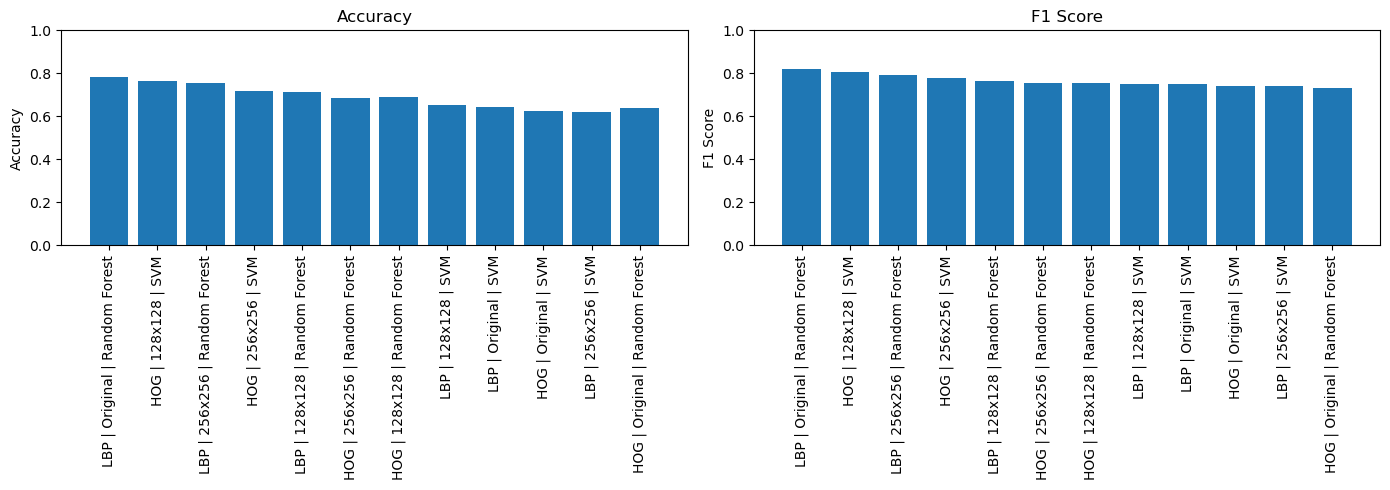

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric, ax in zip(['Accuracy', 'F1 Score'], axes):
    results_df['Experiment'] = (results_df['Feature'] + ' | ' + results_df['Image Size'] + ' | ' + results_df['Classifier'])

    ax.bar(results_df['Experiment'], results_df[metric])

    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

Best feature: LBP
Best image size: Original
Best classifier: Random Forest
Accuracy: 0.7840
F1 Score: 0.8188


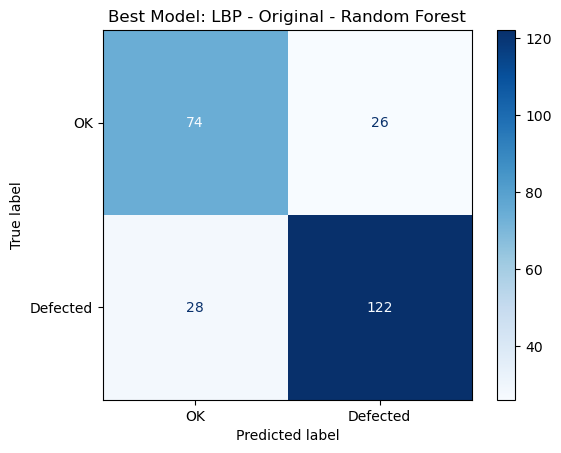

In [ ]:
best_result = max(results, key=lambda result: result['F1 Score'])

print("Best feature:", best_result['Feature'])
print("Best image size:", best_result['Image Size'])
print("Best classifier:", best_result['Classifier'])
print(f"Accuracy: {best_result['Accuracy']:.4f}")
print(f"F1 Score: {best_result['F1 Score']:.4f}")

ConfusionMatrixDisplay.from_predictions(best_result['y_test'], best_result['y_pred'], display_labels=['OK', 'Defected'], cmap='Blues')

plt.title(f"Best Model: {best_result['Feature']} - " f"{best_result['Image Size']} - " f"{best_result['Classifier']}")

plt.show()